<a href="https://colab.research.google.com/github/Jose-Miguel3/TALLER-/blob/main/Proyecto_Final_ADMI1301_Cine_Curso_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ¿Qué hay detrás de una película exitosa? Análisis de datos de la industria cinematográfica

**Curso:** ADMI 1301 — Introducción a la Programación (Segundo semestre de 2026)  
**Profesor:** Oscar Mauricio Cepeda   
**Opción elegida:** Opción B — Análisis de datos e interpretación de resultados  
**Integrantes:** [Nombre Completo 1], [Nombre Completo 2], [Nombre Completo 3]  

---

## 1. Contexto, Problema y Pregunta de Negocio

### Problema o situación
La industria cinematográfica requiere grandes inversiones para producir películas, pero no todas logran recuperar el dinero invertido. Mientras algunas producciones con presupuestos elevados obtienen resultados financieros bajos, otras con menores inversiones alcanzan una recaudación considerable. Esto genera incertidumbre para productoras e inversionistas al decidir en qué proyectos invertir.

### Pregunta de negocio
> **¿Cómo se relacionan el presupuesto, el género, la duración y la calificación del público con la rentabilidad (ganancia neta y retorno sobre la inversión) de una película?**

### Origen de los datos y herramientas utilizadas
* **Fuente de los datos:** Registros históricos de 60 películas internacionales (1997–2023) recopilados de bases públicas de la industria (*TMDB / IMDb / Box Office Mojo*), integrados en este notebook para que el código sea 100% reproducible sin depender de archivos externos.
* **Herramientas del curso aplicadas:** Listas, tuplas, diccionarios, funciones propias, condicionales (`if/elif/else`), ciclos `for` con `enumerate`, arreglos y matrices 2D de **NumPy** (`mean`, `median`, `std`, `sum`, `argmin`, `argmax`, `sort`, `round`, `axis`), tablas y agrupaciones de **pandas** (`DataFrame`, filtrado, `groupby`, `corr`) y gráficos de **Matplotlib** (dispersión, barras e histograma).

In [1]:
# Bloque 1: Importación de librerías vistas en el curso
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print('Librerías cargadas correctamente.')

Librerías cargadas correctamente.


## 2. Estructuras de Datos en Python, Funciones y Limpieza con pandas

Partimos de una **lista de tuplas** con la información de 60 películas (título, año, género, duración en minutos, calificación del público, presupuesto en millones de USD y recaudación en millones de USD).

Para preparar los datos usamos los conceptos fundamentales del curso:
1. **Funciones propias y condicionales (`if / elif / else`):** Para calcular la ganancia neta, el retorno sobre la inversión (ROI) y clasificar cada película según su nivel de presupuesto (*Bajo*, *Medio* o *Alto*).
2. **Ciclo `for` y diccionario:** Para contar cuántas películas hay por género y construir la tabla de trabajo (`DataFrame`) en `pandas`, verificando que no existan valores faltantes ni montos inválidos.

In [2]:
# Bloque 2: Lista de tuplas con los registros de 60 películas
# Estructura de cada tupla: (titulo, anio, genero, duracion_min, calificacion, presupuesto_musd, recaudacion_musd)
datos_peliculas = [
    ('Avatar', 2009, 'Ciencia Ficción', 162, 7.9, 237.0, 2923.7),
    ('Avengers: Endgame', 2019, 'Acción', 181, 8.4, 356.0, 2799.4),
    ('Titanic', 1997, 'Drama', 194, 7.9, 200.0, 2264.7),
    ('Star Wars: The Force Awakens', 2015, 'Ciencia Ficción', 138, 7.8, 245.0, 2071.3),
    ('Jurassic World', 2015, 'Acción', 124, 6.9, 150.0, 1671.5),
    ('The Lion King', 2019, 'Animación', 118, 6.8, 260.0, 1663.1),
    ('Frozen II', 2019, 'Animación', 103, 6.8, 150.0, 1453.7),
    ('Barbie', 2023, 'Comedia', 114, 6.9, 145.0, 1445.6),
    ('The Super Mario Bros. Movie', 2023, 'Animación', 92, 7.0, 100.0, 1361.9),
    ('Top Gun: Maverick', 2022, 'Acción', 130, 8.3, 170.0, 1495.7),
    ('Joker', 2019, 'Drama', 122, 8.4, 55.0, 1074.4),
    ('Oppenheimer', 2023, 'Drama', 180, 8.3, 100.0, 975.6),
    ('Inception', 2010, 'Ciencia Ficción', 148, 8.8, 160.0, 839.0),
    ('Interstellar', 2014, 'Ciencia Ficción', 169, 8.7, 165.0, 731.0),
    ('Parasite', 2019, 'Drama', 132, 8.5, 11.4, 262.6),
    ('Get Out', 2017, 'Terror', 104, 7.8, 4.5, 255.7),
    ('A Quiet Place', 2018, 'Terror', 90, 7.5, 17.0, 340.9),
    ('It', 2017, 'Terror', 135, 7.3, 35.0, 704.2),
    ('The Conjuring', 2013, 'Terror', 112, 7.5, 20.0, 319.5),
    ('Paranormal Activity', 2007, 'Terror', 86, 6.3, 0.015, 193.4),
    ('Split', 2016, 'Terror', 117, 7.3, 9.0, 278.5),
    ('La La Land', 2016, 'Drama', 128, 8.0, 30.0, 472.0),
    ('Whiplash', 2014, 'Drama', 106, 8.5, 3.3, 49.0),
    ('The Hangover', 2009, 'Comedia', 100, 7.7, 35.0, 469.3),
    ('Deadpool', 2016, 'Acción', 108, 8.0, 58.0, 782.6),
    ('John Wick', 2014, 'Acción', 101, 7.4, 20.0, 86.1),
    ('Mad Max: Fury Road', 2015, 'Acción', 120, 8.1, 150.0, 380.4),
    ('Blade Runner 2049', 2017, 'Ciencia Ficción', 164, 8.0, 150.0, 267.5),
    ('Dune', 2021, 'Ciencia Ficción', 155, 8.0, 165.0, 407.6),
    ('Toy Story 4', 2019, 'Animación', 100, 7.7, 200.0, 1073.8),
    ('Coco', 2017, 'Animación', 105, 8.4, 175.0, 814.3),
    ('Inside Out', 2015, 'Animación', 95, 8.1, 175.0, 858.8),
    ('Superbad', 2007, 'Comedia', 113, 7.6, 20.0, 170.8),
    ('Bridesmaids', 2011, 'Comedia', 125, 6.8, 32.5, 288.4),
    ('Crazy Rich Asians', 2018, 'Comedia', 120, 6.9, 30.0, 238.5),
    ('Knives Out', 2019, 'Comedia', 130, 7.9, 40.0, 312.9),
    ('John Carter', 2012, 'Ciencia Ficción', 132, 6.6, 250.0, 284.1),
    ('The Lone Ranger', 2013, 'Acción', 149, 6.4, 215.0, 260.5),
    ('Tomorrowland', 2015, 'Ciencia Ficción', 130, 6.4, 190.0, 209.2),
    ('King Arthur: Legend of the Sword', 2017, 'Acción', 126, 6.7, 175.0, 148.7),
    ('Moonfall', 2022, 'Ciencia Ficción', 130, 5.1, 146.0, 67.3),
    ('Cats', 2019, 'Comedia', 110, 2.8, 95.0, 75.5),
    ('Morbius', 2022, 'Acción', 104, 5.2, 75.0, 167.5),
    ('The Flash', 2023, 'Acción', 144, 6.6, 200.0, 271.3),
    ('Lightyear', 2022, 'Animación', 105, 6.1, 200.0, 226.4),
    ('Strange World', 2022, 'Animación', 102, 5.7, 180.0, 73.6),
    ('Babylon', 2022, 'Drama', 189, 7.1, 80.0, 63.4),
    ('The Northman', 2022, 'Acción', 137, 7.0, 70.0, 69.6),
    ('Everything Everywhere All at Once', 2022, 'Ciencia Ficción', 139, 7.8, 14.3, 143.4),
    ('M3GAN', 2022, 'Terror', 102, 6.3, 12.0, 181.0),
    ('Smile', 2022, 'Terror', 115, 6.5, 17.0, 217.4),
    ('Us', 2019, 'Terror', 116, 6.8, 20.0, 256.1),
    ('The Wolf of Wall Street', 2013, 'Drama', 180, 8.2, 100.0, 406.9),
    ('The Martian', 2015, 'Ciencia Ficción', 144, 8.0, 108.0, 630.6),
    ('Gravity', 2013, 'Ciencia Ficción', 91, 7.7, 100.0, 723.2),
    ('Bohemian Rhapsody', 2018, 'Drama', 134, 7.9, 52.0, 910.8),
    ('Minions', 2015, 'Animación', 91, 6.4, 74.0, 1159.4),
    ('Despicable Me 3', 2017, 'Animación', 89, 6.2, 80.0, 1034.8),
    ('21 Jump Street', 2012, 'Comedia', 109, 7.2, 42.0, 201.6),
    ('The Intouchables', 2011, 'Drama', 112, 8.5, 10.8, 426.6)
]

# Funciones propias con condicionales para métricas financieras y clasificación
def calcular_roi(presupuesto, recaudacion):
    if presupuesto > 0:
        return ((recaudacion - presupuesto) / presupuesto) * 100
    return 0.0

def clasificar_presupuesto(presupuesto):
    if presupuesto < 40:
        return '1. Bajo (< 40M)'
    elif presupuesto <= 140:
        return '2. Medio (40M - 140M)'
    else:
        return '3. Alto (> 140M)'

# Ciclo for y diccionario para contar películas por género antes de armar la tabla
conteo_generos = {}
lista_registros = []

for pelicula in datos_peliculas:
    titulo, anio, genero, duracion, calif, pres, rec = pelicula

    # Actualizar diccionario de conteo por género
    if genero in conteo_generos:
        conteo_generos[genero] += 1
    else:
        conteo_generos[genero] = 1

    ganancia = rec - pres
    roi = calcular_roi(pres, rec)
    nivel = clasificar_presupuesto(pres)
    rentable = ganancia > 0

    lista_registros.append([titulo, anio, genero, duracion, calif, pres, rec, round(ganancia, 2), round(roi, 1), nivel, rentable])

print('Conteo por género (diccionario):', conteo_generos)

# Crear DataFrame de pandas y verificar limpieza de datos
columnas = ['titulo', 'anio', 'genero', 'duracion_min', 'calificacion', 'presupuesto_musd',
            'recaudacion_musd', 'ganancia_musd', 'roi_pct', 'nivel_presupuesto', 'rentable']
df = pd.DataFrame(lista_registros, columns=columnas)

# Verificar datos faltantes y filtrar valores válidos
print('\nValores faltantes por columna:\n', df.isnull().sum())
df = df[(df['presupuesto_musd'] > 0) & (df['recaudacion_musd'] > 0)].copy()

df.head(10)

Conteo por género (diccionario): {'Ciencia Ficción': 12, 'Acción': 11, 'Drama': 10, 'Animación': 10, 'Comedia': 8, 'Terror': 9}

Valores faltantes por columna:
 titulo               0
anio                 0
genero               0
duracion_min         0
calificacion         0
presupuesto_musd     0
recaudacion_musd     0
ganancia_musd        0
roi_pct              0
nivel_presupuesto    0
rentable             0
dtype: int64


,titulo,anio,genero,duracion_min,calificacion,presupuesto_musd,recaudacion_musd,ganancia_musd,roi_pct,nivel_presupuesto,rentable
0,Avatar,2009,Ciencia Ficción,162,7.9,237.0,2923.7,2686.7,1133.6,3. Alto (> 140M),True
1,Avengers: Endgame,2019,Acción,181,8.4,356.0,2799.4,2443.4,686.3,3. Alto (> 140M),True
2,Titanic,1997,Drama,194,7.9,200.0,2264.7,2064.7,1032.3,3. Alto (> 140M),True
3,Star Wars: The Force Awakens,2015,Ciencia Ficción,138,7.8,245.0,2071.3,1826.3,745.4,3. Alto (> 140M),True
4,Jurassic World,2015,Acción,124,6.9,150.0,1671.5,1521.5,1014.3,3. Alto (> 140M),True
5,The Lion King,2019,Animación,118,6.8,260.0,1663.1,1403.1,539.7,3. Alto (> 140M),True
6,Frozen II,2019,Animación,103,6.8,150.0,1453.7,1303.7,869.1,3. Alto (> 140M),True
7,Barbie,2023,Comedia,114,6.9,145.0,1445.6,1300.6,897.0,3. Alto (> 140M),True
8,The Super Mario Bros. Movie,2023,Animación,92,7.0,100.0,1361.9,1261.9,1261.9,2. Medio (40M - 140M),True
9,Top Gun: Maverick,2022,Acción,130,8.3,170.0,1495.7,1325.7,779.8,3. Alto (> 140M),True


## 3. Análisis Numérico con NumPy (Arreglos 1D, Matriz 2D y Ejes)

Utilizamos **NumPy** para realizar cálculos vectorizados sobre los indicadores financieros:
1. **Arreglos 1D (`mean`, `median`, `std`, `min`, `max`, `argmin`, `argmax`, `round`):** Para obtener promedios, medianas, dispersión e identificar las películas con mayor y menor ganancia.
2. **Matriz 2D con `axis` y `.T` (transpuesta):** Organizamos los promedios de *Presupuesto*, *Recaudación* y *Ganancia* por género en una matriz 2D (6 géneros × 3 métricas) para practicar operaciones por filas (`axis=1`) y por columnas (`axis=0`).

In [3]:
# Bloque 3: Análisis estadístico con arreglos 1D de NumPy
titulos_np = df['titulo'].to_numpy()
presupuestos_np = df['presupuesto_musd'].to_numpy()
recaudaciones_np = df['recaudacion_musd'].to_numpy()
ganancias_np = df['ganancia_musd'].to_numpy()
calificaciones_np = df['calificacion'].to_numpy()

print('=== ESTADÍSTICAS GENERALES CON NUMPY ===')
print('Presupuesto  -> Promedio:', np.round(np.mean(presupuestos_np), 2), 'M | Mediana:', np.round(np.median(presupuestos_np), 2), 'M')
print('Recaudación  -> Promedio:', np.round(np.mean(recaudaciones_np), 2), 'M | Mediana:', np.round(np.median(recaudaciones_np), 2), 'M')
print('Ganancia     -> Promedio:', np.round(np.mean(ganancias_np), 2), 'M | Mediana:', np.round(np.median(ganancias_np), 2), 'M')
print('Calificación -> Promedio:', np.round(np.mean(calificaciones_np), 2), '/ 10 | Desv. Estándar:', np.round(np.std(calificaciones_np), 2))

# Uso de np.argmax y np.argmin sobre el array original (sin ordenar) para no perder el índice
idx_mayor_ganancia = np.argmax(ganancias_np)
idx_mayor_perdida = np.argmin(ganancias_np)

print('\nPelícula con MAYOR ganancia neta:', titulos_np[idx_mayor_ganancia], '($' + str(ganancias_np[idx_mayor_ganancia]) + ' M USD)')
print('Película con MAYOR pérdida neta: ', titulos_np[idx_mayor_perdida], '($' + str(ganancias_np[idx_mayor_perdida]) + ' M USD)')

# Uso de np.sort para ver las 5 ganancias más bajas ordenadas de menor a mayor
ganancias_ordenadas = np.sort(ganancias_np)
print('5 peores resultados financieros (ordenados con np.sort):', ganancias_ordenadas[:5])

=== ESTADÍSTICAS GENERALES CON NUMPY ===
Presupuesto  -> Promedio: 106.33 M | Mediana: 97.5 M
Recaudación  -> Promedio: 666.77 M | Mediana: 360.65 M
Ganancia     -> Promedio: 560.44 M | Mediana: 286.2 M
Calificación -> Promedio: 7.29 / 10 | Desv. Estándar: 1.04

Película con MAYOR ganancia neta: Avatar ($2686.7 M USD)
Película con MAYOR pérdida neta:  Strange World ($-106.4 M USD)
5 peores resultados financieros (ordenados con np.sort): [-106.4  -78.7  -26.3  -19.5  -16.6]


## 4. Agrupación y Comparación de Resultados con pandas

Usamos `groupby` y tablas de resumen en **pandas** para responder nuestras preguntas de negocio:
* **Tabla 1:** Desempeño financiero y calificación promedio por género.
* **Tabla 2:** Tasa de éxito y rentabilidad según el nivel de presupuesto invertido.
* **Matriz de correlación (`.corr()`):** Para medir la fuerza de relación entre presupuesto, duración, calificación, recaudación y ganancia.

In [4]:
# Bloque 4: Tablas resumen con pandas
tabla_genero = df.groupby('genero').agg(
    peliculas=('titulo', 'count'),
    presupuesto_prom=('presupuesto_musd', 'mean'),
    recaudacion_prom=('recaudacion_musd', 'mean'),
    ganancia_prom=('ganancia_musd', 'mean'),
    roi_mediano_pct=('roi_pct', 'median'),
    calificacion_prom=('calificacion', 'mean')
).round(2).sort_values(by='ganancia_prom', ascending=False)

print('=== TABLA 1: DESEMPEÑO FINANCIERO Y CALIFICACIÓN POR GÉNERO ===')
display(tabla_genero)

# Matriz 2D de NumPy a partir de la Tabla 1 (columnas: presupuesto_prom, recaudacion_prom, ganancia_prom)
matriz_financiera = tabla_genero[['presupuesto_prom', 'recaudacion_prom', 'ganancia_prom']].to_numpy()
print('Promedio general entre géneros por métrica (axis=0):', np.round(matriz_financiera.mean(axis=0), 2))
print('Matriz transpuesta (.T) forma:', matriz_financiera.T.shape)

tabla_presupuesto = df.groupby('nivel_presupuesto').agg(
    peliculas=('titulo', 'count'),
    porcentaje_rentables=('rentable', lambda x: round(x.mean() * 100, 1)),
    ganancia_prom=('ganancia_musd', 'mean'),
    roi_mediano_pct=('roi_pct', 'median'),
    calificacion_prom=('calificacion', 'mean')
).round(2)

print('\n=== TABLA 2: RESULTADOS SEGÚN NIVEL DE PRESUPUESTO ===')
display(tabla_presupuesto)

# Correlación entre variables numéricas
cols_numericas = ['presupuesto_musd', 'duracion_min', 'calificacion', 'recaudacion_musd', 'ganancia_musd']
print('\n=== CORRELACIÓN ENTRE VARIABLES ===')
display(df[cols_numericas].corr().round(3))

# Películas que tuvieron pérdidas (ganancia < 0)
print('\n=== PELÍCULAS CON PÉRDIDAS FINANCIERAS ===')
display(df[df['ganancia_musd'] < 0][['titulo', 'genero', 'presupuesto_musd', 'recaudacion_musd', 'ganancia_musd', 'calificacion']].sort_values(by='ganancia_musd'))

=== TABLA 1: DESEMPEÑO FINANCIERO Y CALIFICACIÓN POR GÉNERO ===


,peliculas,presupuesto_prom,recaudacion_prom,ganancia_prom,roi_mediano_pct,calificacion_prom
genero,,,,,,
Animación,10,159.40,971.98,812.58,488.30,6.92
Drama,10,64.25,690.60,626.35,1429.05,8.13
Ciencia Ficción,12,160.86,774.82,613.97,383.70,7.57
Acción,11,149.00,739.39,590.39,153.60,7.18
Comedia,8,54.94,400.32,345.39,724.50,6.72
Terror,9,14.95,305.19,290.24,1905.30,7.03


Promedio general entre géneros por métrica (axis=0): [100.57 647.05 546.49]
Matriz transpuesta (.T) forma: (3, 6)

=== TABLA 2: RESULTADOS SEGÚN NIVEL DE PRESUPUESTO ===


,peliculas,porcentaje_rentables,ganancia_prom,roi_mediano_pct,calificacion_prom
nivel_presupuesto,,,,,
1. Bajo (< 40M),19,100.0,263.77,1408.3,7.42
2. Medio (40M - 140M),16,81.2,545.11,652.7,7.08
3. Alto (> 140M),25,88.0,795.73,365.3,7.32



=== CORRELACIÓN ENTRE VARIABLES ===


,presupuesto_musd,duracion_min,calificacion,recaudacion_musd,ganancia_musd
presupuesto_musd,1.000,0.388,-0.009,0.574,0.481
duracion_min,0.388,1.000,0.328,0.271,0.238
calificacion,-0.009,0.328,1.000,0.290,0.312
recaudacion_musd,0.574,0.271,0.290,1.000,0.994
ganancia_musd,0.481,0.238,0.312,0.994,1.000



=== PELÍCULAS CON PÉRDIDAS FINANCIERAS ===


,titulo,genero,presupuesto_musd,recaudacion_musd,ganancia_musd,calificacion
45,Strange World,Animación,180.0,73.6,-106.4,5.7
40,Moonfall,Ciencia Ficción,146.0,67.3,-78.7,5.1
39,King Arthur: Legend of the Sword,Acción,175.0,148.7,-26.3,6.7
41,Cats,Comedia,95.0,75.5,-19.5,2.8
46,Babylon,Drama,80.0,63.4,-16.6,7.1
47,The Northman,Acción,70.0,69.6,-0.4,7.0


## 5. Visualización de Datos con Matplotlib

Construimos cuatro visualizaciones claras con títulos, etiquetas en los ejes y leyendas para interpretar los patrones encontrados:
1. **Figura 1:** Presupuesto vs. Recaudación (dispersión con línea de punto de equilibrio).
2. **Figura 2:** Presupuesto promedio vs. Ganancia neta promedio por género (barras comparativas).
3. **Figura 3:** Distribución de calificaciones del público (histograma) y relación Calificación vs. Ganancia neta.
4. **Figura 4:** Duración de la película vs. Recaudación en taquilla.

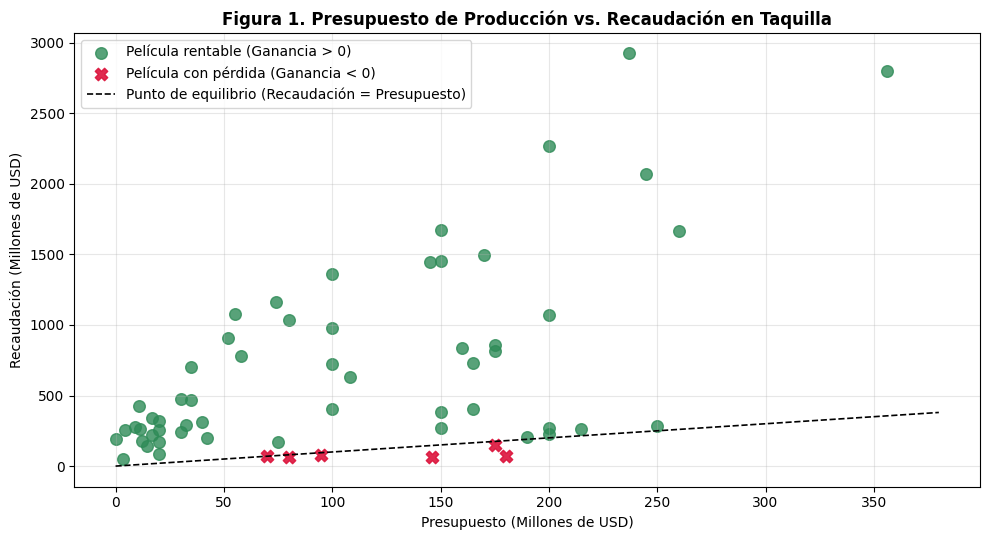

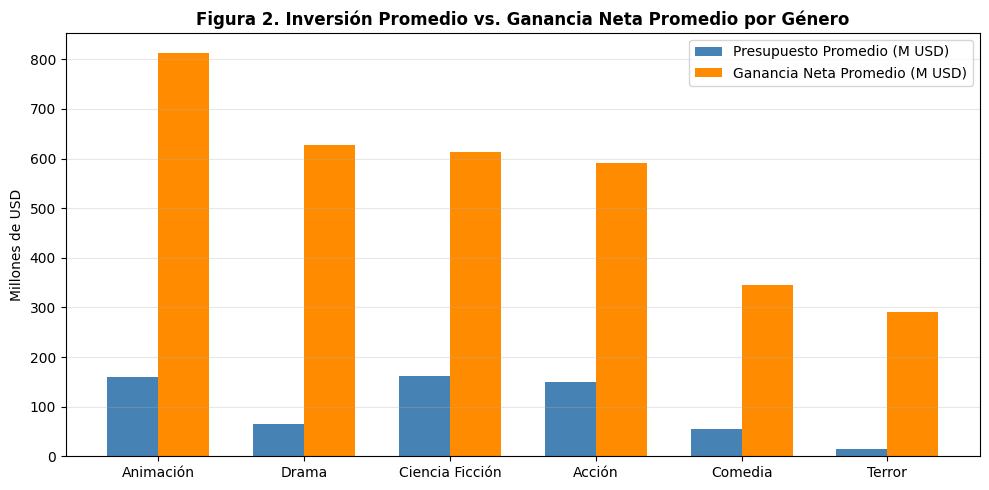

In [5]:
# Bloque 5: Visualizaciones con Matplotlib
# --- FIGURA 1: Presupuesto vs. Recaudación ---
plt.figure(figsize=(10, 5.5))
rentables = df[df['rentable'] == True]
no_rentables = df[df['rentable'] == False]

plt.scatter(rentables['presupuesto_musd'], rentables['recaudacion_musd'], color='seagreen', alpha=0.8, s=70, label='Película rentable (Ganancia > 0)')
plt.scatter(no_rentables['presupuesto_musd'], no_rentables['recaudacion_musd'], color='crimson', alpha=0.9, s=80, marker='X', label='Película con pérdida (Ganancia < 0)')

# Línea de punto de equilibrio (Recaudación = Presupuesto)
x_eq = np.linspace(0, 380, 100)
plt.plot(x_eq, x_eq, color='black', linestyle='--', linewidth=1.2, label='Punto de equilibrio (Recaudación = Presupuesto)')

plt.title('Figura 1. Presupuesto de Producción vs. Recaudación en Taquilla', fontsize=12, fontweight='bold')
plt.xlabel('Presupuesto (Millones de USD)')
plt.ylabel('Recaudación (Millones de USD)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# --- FIGURA 2: Presupuesto Promedio vs. Ganancia Neta Promedio por Género ---
generos = tabla_genero.index
posiciones = np.arange(len(generos))
ancho = 0.35

plt.figure(figsize=(10, 5))
plt.bar(posiciones - ancho/2, tabla_genero['presupuesto_prom'], width=ancho, color='steelblue', label='Presupuesto Promedio (M USD)')
plt.bar(posiciones + ancho/2, tabla_genero['ganancia_prom'], width=ancho, color='darkorange', label='Ganancia Neta Promedio (M USD)')

plt.title('Figura 2. Inversión Promedio vs. Ganancia Neta Promedio por Género', fontsize=12, fontweight='bold')
plt.xticks(posiciones, generos)
plt.ylabel('Millones de USD')
plt.grid(True, axis='y', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

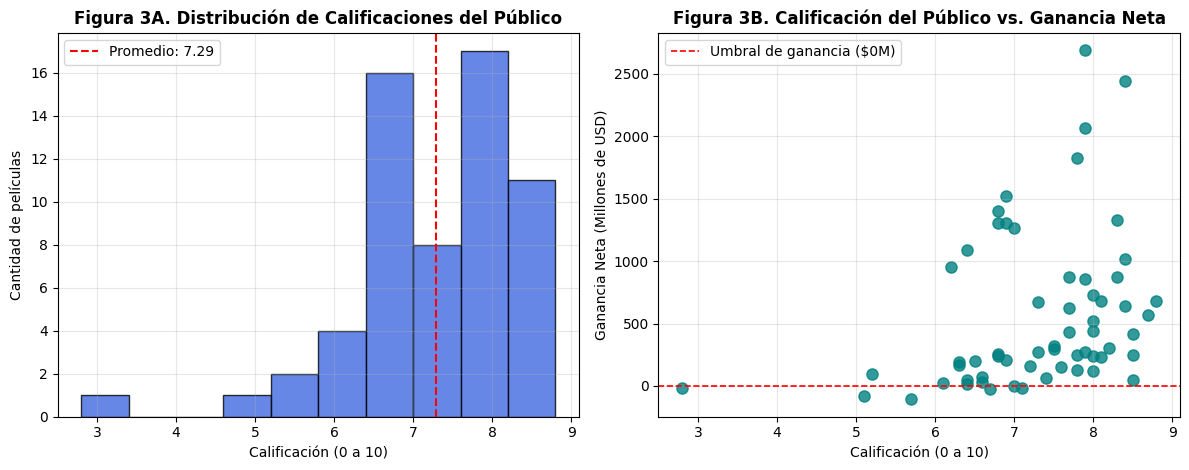

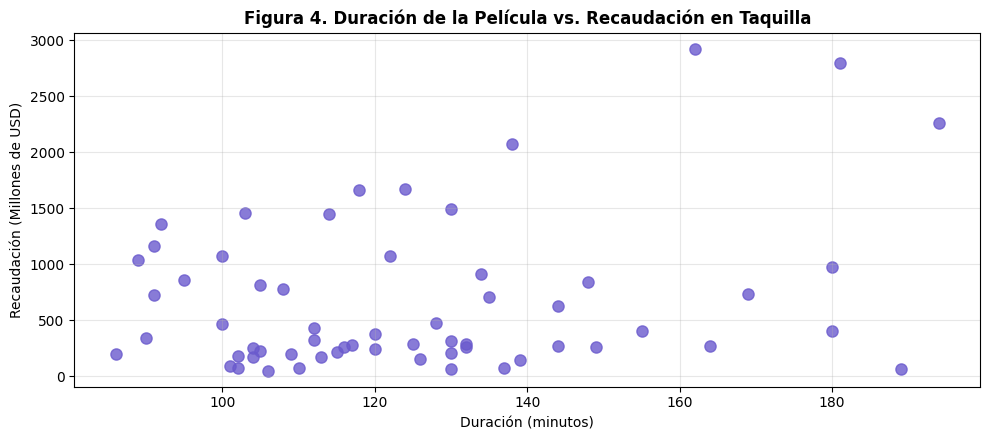

In [6]:
# --- FIGURA 3A y 3B: Histograma de Calificaciones y Calificación vs. Ganancia ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Histograma de calificaciones
axes[0].hist(df['calificacion'], bins=10, color='royalblue', edgecolor='black', alpha=0.8)
axes[0].axvline(df['calificacion'].mean(), color='red', linestyle='--', label=f"Promedio: {df['calificacion'].mean():.2f}")
axes[0].set_title('Figura 3A. Distribución de Calificaciones del Público', fontweight='bold')
axes[0].set_xlabel('Calificación (0 a 10)')
axes[0].set_ylabel('Cantidad de películas')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Dispersión Calificación vs. Ganancia
axes[1].scatter(df['calificacion'], df['ganancia_musd'], color='teal', alpha=0.8, s=65)
axes[1].axhline(0, color='red', linestyle='--', linewidth=1.2, label='Umbral de ganancia ($0M)')
axes[1].set_title('Figura 3B. Calificación del Público vs. Ganancia Neta', fontweight='bold')
axes[1].set_xlabel('Calificación (0 a 10)')
axes[1].set_ylabel('Ganancia Neta (Millones de USD)')
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

# --- FIGURA 4: Duración vs. Recaudación ---
plt.figure(figsize=(10, 4.5))
plt.scatter(df['duracion_min'], df['recaudacion_musd'], color='slateblue', alpha=0.8, s=65)
plt.title('Figura 4. Duración de la Película vs. Recaudación en Taquilla', fontsize=12, fontweight='bold')
plt.xlabel('Duración (minutos)')
plt.ylabel('Recaudación (Millones de USD)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Interpretación de Resultados, Conclusiones y Limitaciones

### Interpretación de los hallazgos
1. **Un presupuesto alto aumenta la recaudación bruta, pero no garantiza rentabilidad:** La correlación entre presupuesto y recaudación es moderada-alta ($r = 0.574$), pero las 6 películas que perdieron dinero en la muestra (*Strange World*, *Moonfall*, *King Arthur*, *Cats*, *Babylon* y *The Northman*) tuvieron inversiones altas o medias (entre $70M y $180M USD). En cambio, el **100%** de las películas de presupuesto bajo (< $40M USD) fueron rentables y obtuvieron el mayor retorno porcentual mediano (**1,408.3%**).
2. **Diferencia estratégica entre géneros:**
   * **Animación** genera la mayor ganancia neta promedio (**$812.58 M USD**), pero requiere presupuestos elevados ($159.40 M USD en promedio).
   * **Terror** requiere la menor inversión promedio (**$14.95 M USD**), genera una ganancia promedio muy atractiva (**$290.24 M USD**) y logra el mayor ROI mediano (**1,905.3%**), sin pérdidas en la muestra.
   * **Drama** alcanza la calificación promedio más alta (**8.13 / 10**) con presupuestos moderados ($64.25 M USD), logrando una ganancia promedio de **$626.35 M USD**.
3. **La calificación del público actúa como filtro de riesgo:** Las películas con calificaciones inferiores a **6.0** no lograron éxitos financieros relevantes y concentraron las mayores pérdidas. Por el contrario, las producciones con calificación superior a **7.8** lideraron tanto la ganancia total (*Avatar*, *Avengers: Endgame*) como el retorno sobre la inversión (*Get Out*, *Joker*, *Parasite*).
4. **La duración tiene baja relación con la taquilla:** La correlación entre duración y recaudación es débil ($r = 0.271$). Existen éxitos tanto en películas cortas de ~90 minutos (*Super Mario Bros.*, *Minions*) como en producciones largas de más de 160 minutos (*Avatar*, *Titanic*).

### Recomendaciones para productoras e inversionistas
* **Balancear el portafolio de inversión:** Combinar producciones de alto presupuesto en **Animación** o **Ciencia Ficción/Acción** (respaldadas por franquicias sólidas) con proyectos de **Terror** o **Drama** de presupuesto bajo o medio, que ofrecen alto retorno porcentual con menor exposición al riesgo.
* **Controlar la calidad antes del lanzamiento:** En proyectos de más de $140 M USD, una baja aceptación del público (< 6.5) genera pérdidas difíciles de compensar.

### Limitaciones del análisis
* Los datos consideran únicamente el presupuesto de producción y la recaudación en taquilla global, sin incluir gastos de publicidad y distribución ni ingresos posteriores por *streaming* o venta de licencias.
* La muestra reúne 60 películas representativas de distintos años y géneros, sin ajustar los valores monetarios por inflación.

---

## 7. Nota sobre el uso de Inteligencia Artificial
* **Herramienta utilizada:** Gemini (asistente de IA).
* **Tareas apoyadas:** Organización de la estructura del notebook, revisión de sintaxis en `NumPy`, `pandas` y `Matplotlib`, y apoyo en la redacción de las secciones explicativas.
* **Verificación:** Todo el código fue ejecutado y validado paso a paso en Python, comprobando manualmente cada tabla, correlación y gráfico generado a partir de los datos.